## **Importing Libraries**
---

In [ ]:

# Importing Numpy & Pandas for data processing & data wrangling
import numpy as np
import pandas as pd

# Importing  tools for visualization
import matplotlib.pyplot as plt
import seaborn as sns

# Import evaluation metric libraries
from sklearn.metrics import confusion_matrix, accuracy_score, precision_score, recall_score, f1_score, classification_report

# Word Cloud library
from wordcloud import WordCloud, STOPWORDS

# Library used for data preprocessing
from sklearn.feature_extraction.text import CountVectorizer

# Import model selection libraries
from sklearn.model_selection import train_test_split

# Library used for ML Model implementation
from sklearn.naive_bayes import MultinomialNB

# Importing the Pipeline class from scikit-learn
from sklearn.pipeline import Pipeline

# Library used for ignore warnings
import warnings
warnings.filterwarnings('ignore')
%matplotlib inline
     

## 1. **UNDERSTANDING THE DATASET FOR EXPLORATORY DATA ANALYSIS**
---

## **Data Loading**

In [184]:
df = pd.read_csv('data/spam.csv', encoding='latin-1')

# **Dataset First Look**

In [185]:

df.head()

,v1,v2,Unnamed: 2,Unnamed: 3,Unnamed: 4
0,ham,"Go until jurong point, crazy.. Available only ...",NaN,NaN,NaN
1,ham,Ok lar... Joking wif u oni...,NaN,NaN,NaN
2,spam,Free entry in 2 a wkly comp to win FA Cup fina...,NaN,NaN,NaN
3,ham,U dun say so early hor... U c already then say...,NaN,NaN,NaN
4,ham,"Nah I don't think he goes to usf, he lives aro...",NaN,NaN,NaN


## **Dataset Rows & Columns count**

In [186]:
# Dataset Rows & Columns count
# Checking number of rows and columns of the dataset using shape
print("Number of rows are: ",df.shape[0])
print("Number of columns are: ",df.shape[1])

Number of rows are:  5572
Number of columns are:  5


# **Dataset Information**

In [187]:
# Dataset Info
# Checking information about the dataset using info
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5572 entries, 0 to 5571
Data columns (total 5 columns):
 #   Column      Non-Null Count  Dtype 
---  ------      --------------  ----- 
 0   v1          5572 non-null   object
 1   v2          5572 non-null   object
 2   Unnamed: 2  50 non-null     object
 3   Unnamed: 3  12 non-null     object
 4   Unnamed: 4  6 non-null      object
dtypes: object(5)
memory usage: 217.8+ KB


## **Duplicate Values**

In [188]:

# Dataset Duplicate Value Count
dup = df.duplicated().sum()
print(f'number of duplicated rows are {dup}')

number of duplicated rows are 403


## **Missing Values/Null Values Count**

In [189]:

# Missing Values/Null Values Count
df.isnull().sum()

v1               0
v2               0
Unnamed: 2    5522
Unnamed: 3    5560
Unnamed: 4    5566
dtype: int64

## 2. **Understanding the Variables Associated with the Dataset**
---

In [190]:
# Dataset Columns
df.columns

Index(['v1', 'v2', 'Unnamed: 2', 'Unnamed: 3', 'Unnamed: 4'], dtype='object')

In [191]:

# Dataset Describe (all columns included)
df.describe(include= 'all').round(2)

,v1,v2,Unnamed: 2,Unnamed: 3,Unnamed: 4
count,5572,5572,50,12,6
unique,2,5169,43,10,5
top,ham,"Sorry, I'll call later","bt not his girlfrnd... G o o d n i g h t . . .@""","MK17 92H. 450Ppw 16""","GNT:-)"""
freq,4825,30,3,2,2


In [192]:

# Check Unique Values for each variable using a for loop.
for i in df.columns.tolist():
  print("No. of unique values in",i,"is",df[i].nunique())
     

No. of unique values in v1 is 2
No. of unique values in v2 is 5169
No. of unique values in Unnamed: 2 is 43
No. of unique values in Unnamed: 3 is 10
No. of unique values in Unnamed: 4 is 5


## 3. **Data Wrangling**
---

In [193]:
df.rename(columns={"v1": "Category", "v2": "Message"}, inplace=True)

In [194]:

# Removing the all unnamed columns (its include much number of missing values)
df.drop(columns={'Unnamed: 2','Unnamed: 3','Unnamed: 4'}, inplace=True)

In [195]:

# Create a binary 'Spam' column: 1 for 'spam' and 0 for 'ham', based on the 'Category' column.
df['Spam'] = df['Category'].apply(lambda x: 1 if x == 'spam' else 0)
# Display the updated DataFrame with the new 'Spam' column
df.head()

,Category,Message,Spam
0,ham,"Go until jurong point, crazy.. Available only ...",0
1,ham,Ok lar... Joking wif u oni...,0
2,spam,Free entry in 2 a wkly comp to win FA Cup fina...,1
3,ham,U dun say so early hor... U c already then say...,0
4,ham,"Nah I don't think he goes to usf, he lives aro...",0


## 4. **Data Vizualization, Understand the relationships between variables**
---

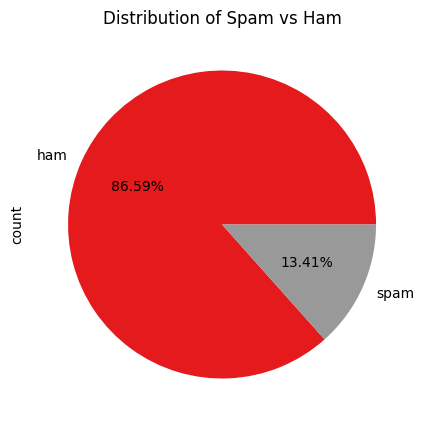

In [196]:
spread = df['Category'].value_counts()
plt.rcParams['figure.figsize'] = (5,5)

spread.plot(kind = 'pie', autopct='%1.2f%%', cmap='Set1')
plt.title(f'Distribution of Spam vs Ham')

plt.show()

In [197]:
df_spam = df[df['Category']=='spam'].copy()
df_spam.head()

,Category,Message,Spam
2,spam,Free entry in 2 a wkly comp to win FA Cup fina...,1
5,spam,FreeMsg Hey there darling it's been 3 week's n...,1
8,spam,WINNER!! As a valued network customer you have...,1
9,spam,Had your mobile 11 months or more? U R entitle...,1
11,spam,"SIX chances to win CASH! From 100 to 20,000 po...",1


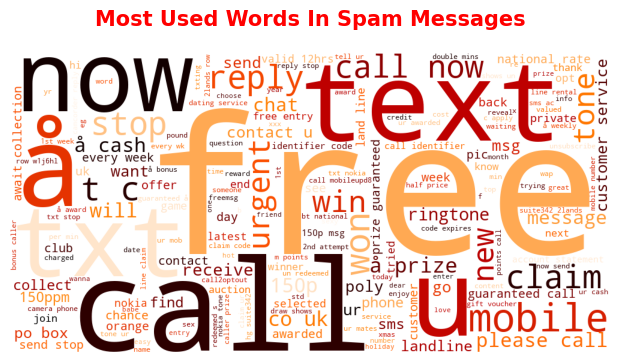

In [198]:
# Create a String to Store All The Words
comment_words = ''

# Remove The Stopwords
stopwords = set(STOPWORDS)

# Iterate Through The Column
for val in df_spam.Message:

    # Typecaste Each Val to String
    val = str(val)

    # Split The Value
    tokens = val.split()

    # Converts Each Token into lowercase
    for i in range(len(tokens)):
        tokens[i] = tokens[i].lower()

    comment_words += " ".join(tokens)+" "

# Set Parameters
wordcloud = WordCloud(width = 1000, height = 500,
                background_color ='white',
                stopwords = stopwords,
                min_font_size = 10,
                max_words = 1000,
                colormap = 'gist_heat_r').generate(comment_words)

# Set Labels
plt.figure(figsize = (6,6), facecolor = None)
plt.title('Most Used Words In Spam Messages', fontsize = 15, pad=20,  color='red', weight='bold')
plt.imshow(wordcloud)
plt.axis("off")
plt.tight_layout(pad = 0)

# Display Chart
plt.show()
     


## 5. **Feature Engineering & Data Pre-processing**
---

In [199]:

X_train,X_test,y_train,y_test=train_test_split(df.Message,df.Spam,test_size=0.25)

#### Logistic Regression

In [200]:
from sklearn.linear_model import LogisticRegression
from sklearn.feature_extraction.text import TfidfVectorizer

# Text to TF-IDF
vectorizer = CountVectorizer()
X_train_vec = vectorizer.fit_transform(X_train)
X_test_vec = vectorizer.transform(X_test)

# Train model
lr = LogisticRegression(max_iter=500, C=1.0)
lr.fit(X_train_vec, y_train)

# Predictions
y_pred_train = lr.predict(X_train_vec)
y_pred_test = lr.predict(X_test_vec)
y_prob_train = lr.predict_proba(X_train_vec)[:,1]
y_prob_test = lr.predict_proba(X_test_vec)[:,1]


In [ ]:

acc_train = accuracy_score(y_train, y_pred_train)
acc_test = accuracy_score(y_test, y_pred_test)
prec_train = precision_score(y_train, y_pred_train)
prec_test = precision_score(y_test, y_pred_test)
recall_train = recall_score(y_train, y_pred_train)
recall_test = recall_score(y_test, y_pred_test)
f1_train = f1_score(y_train, y_pred_train)
f1_test = f1_score(y_test, y_pred_test)

print(f"Train Accuracy: {acc_train:.4f}, Precision: {prec_train:.4f}, Recall: {recall_train:.4f}, F1-score: {f1_train:.4f}")
print(f"Test  Accuracy: {acc_test:.4f}, Precision: {prec_test:.4f}, Recall: {recall_test:.4f}, F1-score: {f1_test:.4f}")


print("\nClassification Report - Train:\n", classification_report(y_train, y_pred_train))
print("\nClassification Report - Test:\n", classification_report(y_test, y_pred_test))


Train Accuracy: 0.9981, Precision: 1.0000, Recall: 0.9855, F1-score: 0.9927
Test  Accuracy: 0.9799, Precision: 0.9669, Recall: 0.8883, F1-score: 0.9259

Classification Report - Train:
               precision    recall  f1-score   support

           0       1.00      1.00      1.00      3629
           1       1.00      0.99      0.99       550

    accuracy                           1.00      4179
   macro avg       1.00      0.99      1.00      4179
weighted avg       1.00      1.00      1.00      4179


Classification Report - Test:
               precision    recall  f1-score   support

           0       0.98      0.99      0.99      1196
           1       0.97      0.89      0.93       197

    accuracy                           0.98      1393
   macro avg       0.97      0.94      0.96      1393
weighted avg       0.98      0.98      0.98      1393



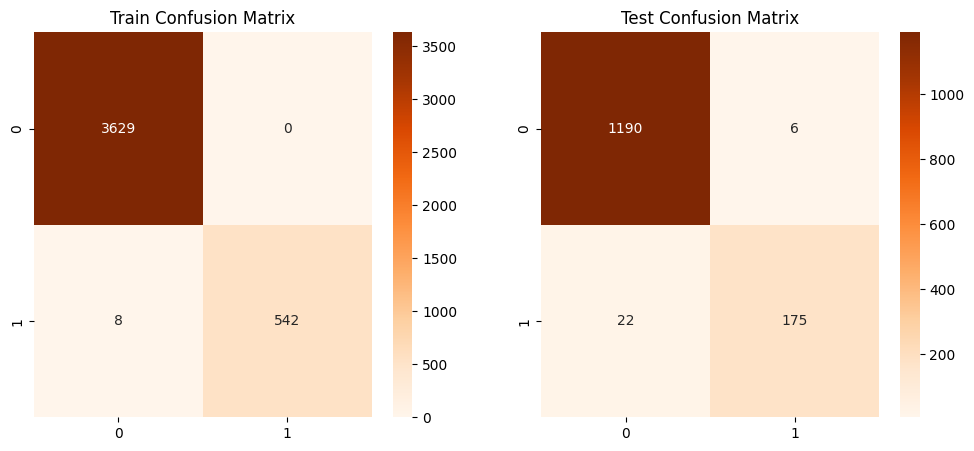

In [ ]:

fig, ax = plt.subplots(1,2, figsize=(12,5))
sns.heatmap(confusion_matrix(y_train, y_pred_train), annot=True, fmt='d', ax=ax[0], cmap='Oranges')
ax[0].set_title("Train Confusion Matrix")
sns.heatmap(confusion_matrix(y_test, y_pred_test), annot=True, fmt='d', ax=ax[1], cmap='Oranges')
ax[1].set_title("Test Confusion Matrix")
plt.show()


#### Decision Tree Classifier

In [203]:
from sklearn.tree import DecisionTreeClassifier

vectorizer = CountVectorizer()
X_train_vec = vectorizer.fit_transform(X_train)
X_test_vec = vectorizer.transform(X_test)

dt = DecisionTreeClassifier(max_depth=None, random_state=42)
dt.fit(X_train_vec, y_train)

y_pred_train = dt.predict(X_train_vec)
y_pred_test = dt.predict(X_test_vec)
y_prob_train = dt.predict_proba(X_train_vec)[:,1]
y_prob_test = dt.predict_proba(X_test_vec)[:,1]


In [204]:
acc_train = accuracy_score(y_train, y_pred_train)
acc_test = accuracy_score(y_test, y_pred_test)
prec_train = precision_score(y_train, y_pred_train)
prec_test = precision_score(y_test, y_pred_test)
recall_train = recall_score(y_train, y_pred_train)
recall_test = recall_score(y_test, y_pred_test)
f1_train = f1_score(y_train, y_pred_train)
f1_test = f1_score(y_test, y_pred_test)

print(f"Train Accuracy: {acc_train:.4f}, Precision: {prec_train:.4f}, Recall: {recall_train:.4f}, F1-score: {f1_train:.4f}")
print(f"Test  Accuracy: {acc_test:.4f}, Precision: {prec_test:.4f}, Recall: {recall_test:.4f}, F1-score: {f1_test:.4f}")

print("\nClassification Report - Train:\n", classification_report(y_train, y_pred_train))
print("\nClassification Report - Test:\n", classification_report(y_test, y_pred_test))

Train Accuracy: 1.0000, Precision: 1.0000, Recall: 1.0000, F1-score: 1.0000
Test  Accuracy: 0.9612, Precision: 0.8865, Recall: 0.8325, F1-score: 0.8586

Classification Report - Train:
               precision    recall  f1-score   support

           0       1.00      1.00      1.00      3629
           1       1.00      1.00      1.00       550

    accuracy                           1.00      4179
   macro avg       1.00      1.00      1.00      4179
weighted avg       1.00      1.00      1.00      4179


Classification Report - Test:
               precision    recall  f1-score   support

           0       0.97      0.98      0.98      1196
           1       0.89      0.83      0.86       197

    accuracy                           0.96      1393
   macro avg       0.93      0.91      0.92      1393
weighted avg       0.96      0.96      0.96      1393



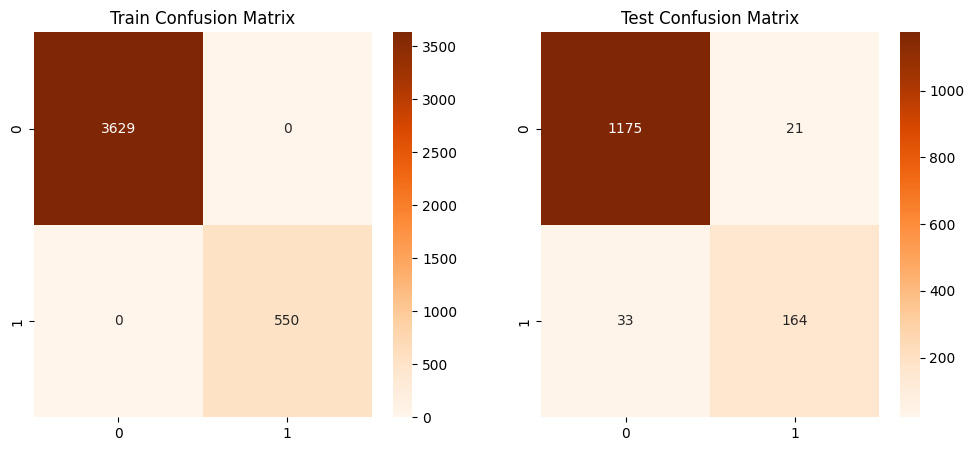

In [205]:
fig, ax = plt.subplots(1,2, figsize=(12,5))
sns.heatmap(confusion_matrix(y_train, y_pred_train), annot=True, fmt='d', ax=ax[0], cmap='Oranges')
ax[0].set_title("Train Confusion Matrix")
sns.heatmap(confusion_matrix(y_test, y_pred_test), annot=True, fmt='d', ax=ax[1], cmap='Oranges')
ax[1].set_title("Test Confusion Matrix")
plt.show()

#### Multinomial Naive Bayes

In [206]:
vectorizer = CountVectorizer()
X_train_vec = vectorizer.fit_transform(X_train)
X_test_vec = vectorizer.transform(X_test)

nb = MultinomialNB(alpha=1.0)
nb.fit(X_train_vec, y_train)

y_pred_train = nb.predict(X_train_vec)
y_pred_test = nb.predict(X_test_vec)
y_prob_train = nb.predict_proba(X_train_vec)[:,1]
y_prob_test = nb.predict_proba(X_test_vec)[:,1]

In [207]:
acc_train = accuracy_score(y_train, y_pred_train)
acc_test = accuracy_score(y_test, y_pred_test)
prec_train = precision_score(y_train, y_pred_train)
prec_test = precision_score(y_test, y_pred_test)
recall_train = recall_score(y_train, y_pred_train)
recall_test = recall_score(y_test, y_pred_test)
f1_train = f1_score(y_train, y_pred_train)
f1_test = f1_score(y_test, y_pred_test)
print(f"Train Accuracy: {acc_train:.4f}, Precision: {prec_train:.4f}, Recall: {recall_train:.4f}, F1-score: {f1_train:.4f}")
print(f"Test  Accuracy: {acc_test:.4f}, Precision: {prec_test:.4f}, Recall: {recall_test:.4f}, F1-score: {f1_test:.4f}")

print("\nClassification Report - Train:\n", classification_report(y_train, y_pred_train))
print("\nClassification Report - Test:\n", classification_report(y_test, y_pred_test))



Train Accuracy: 0.9933, Precision: 0.9815, Recall: 0.9673, F1-score: 0.9744
Test  Accuracy: 0.9878, Precision: 0.9787, Recall: 0.9340, F1-score: 0.9558

Classification Report - Train:
               precision    recall  f1-score   support

           0       1.00      1.00      1.00      3629
           1       0.98      0.97      0.97       550

    accuracy                           0.99      4179
   macro avg       0.99      0.98      0.99      4179
weighted avg       0.99      0.99      0.99      4179


Classification Report - Test:
               precision    recall  f1-score   support

           0       0.99      1.00      0.99      1196
           1       0.98      0.93      0.96       197

    accuracy                           0.99      1393
   macro avg       0.98      0.97      0.97      1393
weighted avg       0.99      0.99      0.99      1393



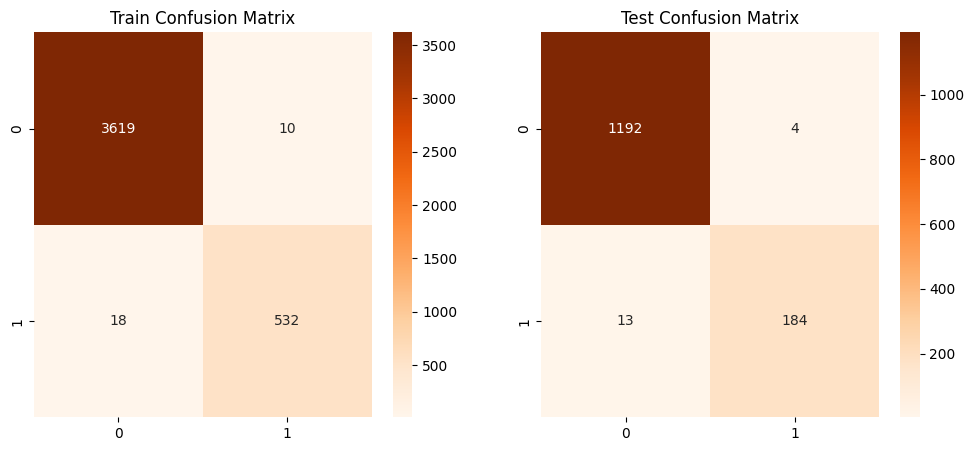

In [208]:
fig, ax = plt.subplots(1,2, figsize=(12,5))
sns.heatmap(confusion_matrix(y_train, y_pred_train), annot=True, fmt='d', ax=ax[0], cmap='Oranges')
ax[0].set_title("Train Confusion Matrix")
sns.heatmap(confusion_matrix(y_test, y_pred_test), annot=True, fmt='d', ax=ax[1], cmap='Oranges')
ax[1].set_title("Test Confusion Matrix")
plt.show()

## 7. **Email Spam Detection System**
---

In [209]:
def detect_spam(email_text):
    email_vec = vectorizer.transform([email_text])
    
    prediction = nb.predict(email_vec)

    if prediction[0] == 0:
        return "This is a Ham Email!"
    else:
        return "This is a Spam Email!"

In [210]:
sample_email = 'Free Tickets for IPL'
result = detect_spam(sample_email)
print(result)

This is a Spam Email!


In [211]:
sample_email= "Congratulations! You've won a $1,000,000 prize. Claim it now!"
result = detect_spam(sample_email)
print(result)

This is a Spam Email!


In [212]:
sample_email = 'Notification: Your monthly utility bill is now available for viewing online.'
result = detect_spam(sample_email)
print(result)

This is a Ham Email!


In [213]:
sample_email = 'Congratulations! You have won a lottery of $1,000,000. Click here to claim your prize.'
result = detect_spam(sample_email)
print(result)

This is a Spam Email!


In [214]:
sample_email = "Happy birthday! We hope you have a fantastic day celebrating."
result = detect_spam(sample_email)
print(result)

This is a Ham Email!
